# K-Means for Densities with Reverse KL Barycenters: Nerd 🤓 vs Duck 🦆

We treat two emoji images as 2D probability distributions, draw many noisy samples from each, fit a KDE to every sample, and cluster the resulting 40 densities with a K-means (Lloyd) algorithm in which

- the **distance** is KL divergence, and
- the **cluster center** is the **reverse KL barycenter** (normalised geometric mean) of the cluster's densities.

We then add constraints to the barycenter, first with a closed form and then with a general convex solver.

## 1. Images → weighted 2D point clouds

Each image is converted to grayscale $G_{ij}\in[0,255]$. For every pixel:

1. invert brightness, $w_{ij}=255-G_{ij}$, and set $w_{ij}=0$ if $w_{ij}<15$ (background removal);
2. square the weights to sharpen contrast, then normalise: $p_{ij}=w_{ij}^2/\sum w^2$;
3. map pixel $(i,j)$ to the point $(\text{col}_j,\,-\text{row}_i)$ and standardise all points by their mean and standard deviation (the minus sign makes $y$ point upward).

The result is a set of candidate points with sampling probabilities: darker pixels are sampled more often.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA = "../data"
FIG = "../figures"
os.makedirs(FIG, exist_ok=True)

nerd = np.array(Image.open(f"{DATA}/nerd.png").convert("L"))
duck = np.array(Image.open(f"{DATA}/Duck.png").convert("L"))

def build_weight_system(img_gray):
    weight = (255 - img_gray).astype(float)
    weight[weight < 15] = 0
    rows, cols = np.where(weight > 0)
    probs = weight[rows, cols] ** 2
    probs = probs / probs.sum()
    xy = np.column_stack([cols, -rows]).astype(float)
    xy = (xy - xy.mean(axis=0)) / xy.std()
    return xy, probs

nerd_xy, nerd_probs = build_weight_system(nerd)
duck_xy, duck_probs = build_weight_system(duck)
print(f"Nerd: {len(nerd_xy)} candidate pixels, probs sum to {nerd_probs.sum():.6f}")
print(f"Duck: {len(duck_xy)} candidate pixels, probs sum to {duck_probs.sum():.6f}")

Nerd: 320318 candidate pixels, probs sum to 1.000000
Duck: 303548 candidate pixels, probs sum to 1.000000


## 2. Sampling and 2D kernel density estimation

For each emoji we repeat $M=20$ times:

1. draw $N=1300$ points i.i.d. from the weighted point cloud;
2. fit a 2D Gaussian KDE (bandwidth $=0.45\times$ Scott's rule) and evaluate it on a $64\times64$ grid over $[-3,3]^2$;
3. normalise to a discrete distribution, add a floor $\varepsilon=1/(100\cdot 64^2)$ and renormalise, so that every cell has positive mass and all KL divergences are finite.

Finally, each KDE is perturbed with small Gaussian noise (standard deviation $5\%$ of its mean cell value), clipped at $0$ and renormalised, to make the clustering problem slightly harder. This gives $2M=40$ discrete 2D distributions.

In [2]:
from scipy.stats import gaussian_kde

class CustomBandwidthKDE(gaussian_kde):
    def __init__(self, dataset, bw_scale=1.0):
        self.bw_scale = bw_scale
        super().__init__(dataset)

    def covariance_factor(self):
        return super().covariance_factor() * self.bw_scale

def sample_and_kde(xy, probs, N, grid_points, grid_size, bandwidth_scale=0.45):
    # probs=None means uniform sampling over the foreground pixels (used in Section 4)
    idx = np.random.choice(len(xy), size=N, replace=True, p=probs)
    kde = CustomBandwidthKDE(xy[idx].T, bw_scale=bandwidth_scale)
    density = kde(grid_points).reshape(grid_size, grid_size)
    density = density / density.sum()
    density += 1 / (100 * density.size)
    return density / density.sum()

def add_noise_to_distributions(kde_arrays, noise_level=0.05, seed=42):
    rng = np.random.default_rng(seed)
    noisy = np.copy(kde_arrays)
    for m in range(len(noisy)):
        noisy[m] = noisy[m] + rng.normal(0.0, noise_level * noisy[m].mean(), size=noisy[m].shape)
        noisy[m] = np.clip(noisy[m], 0, None)
        noisy[m] += 1 / (100 * noisy[m].size)
        noisy[m] /= noisy[m].sum()
    return noisy

grid_size = 64
x_edge = np.linspace(-3, 3, grid_size)
xx, yy = np.meshgrid(x_edge, x_edge)
grid_points = np.vstack([xx.ravel(), yy.ravel()])

M, N = 20, 1300

def make_kdes(weighted=True, seed=305):
    np.random.seed(seed)
    pn = nerd_probs if weighted else None
    pd = duck_probs if weighted else None
    kn = np.array([sample_and_kde(nerd_xy, pn, N, grid_points, grid_size) for _ in range(M)])
    kd = np.array([sample_and_kde(duck_xy, pd, N, grid_points, grid_size) for _ in range(M)])
    kn = add_noise_to_distributions(kn, 0.05, seed=123)
    kd = add_noise_to_distributions(kd, 0.05, seed=456)
    return kn, kd

kdes_nerd, kdes_duck = make_kdes(weighted=True)
all_kdes = np.concatenate([kdes_nerd, kdes_duck], axis=0)   # shape (40, 64, 64)
true_labels = np.array([0] * M + [1] * M)                    # 0 = nerd, 1 = duck
print("all_kdes shape:", all_kdes.shape, "| all sum to 1:", np.allclose(all_kdes.sum(axis=(1, 2)), 1))

all_kdes shape: (40, 64, 64) | all sum to 1: True


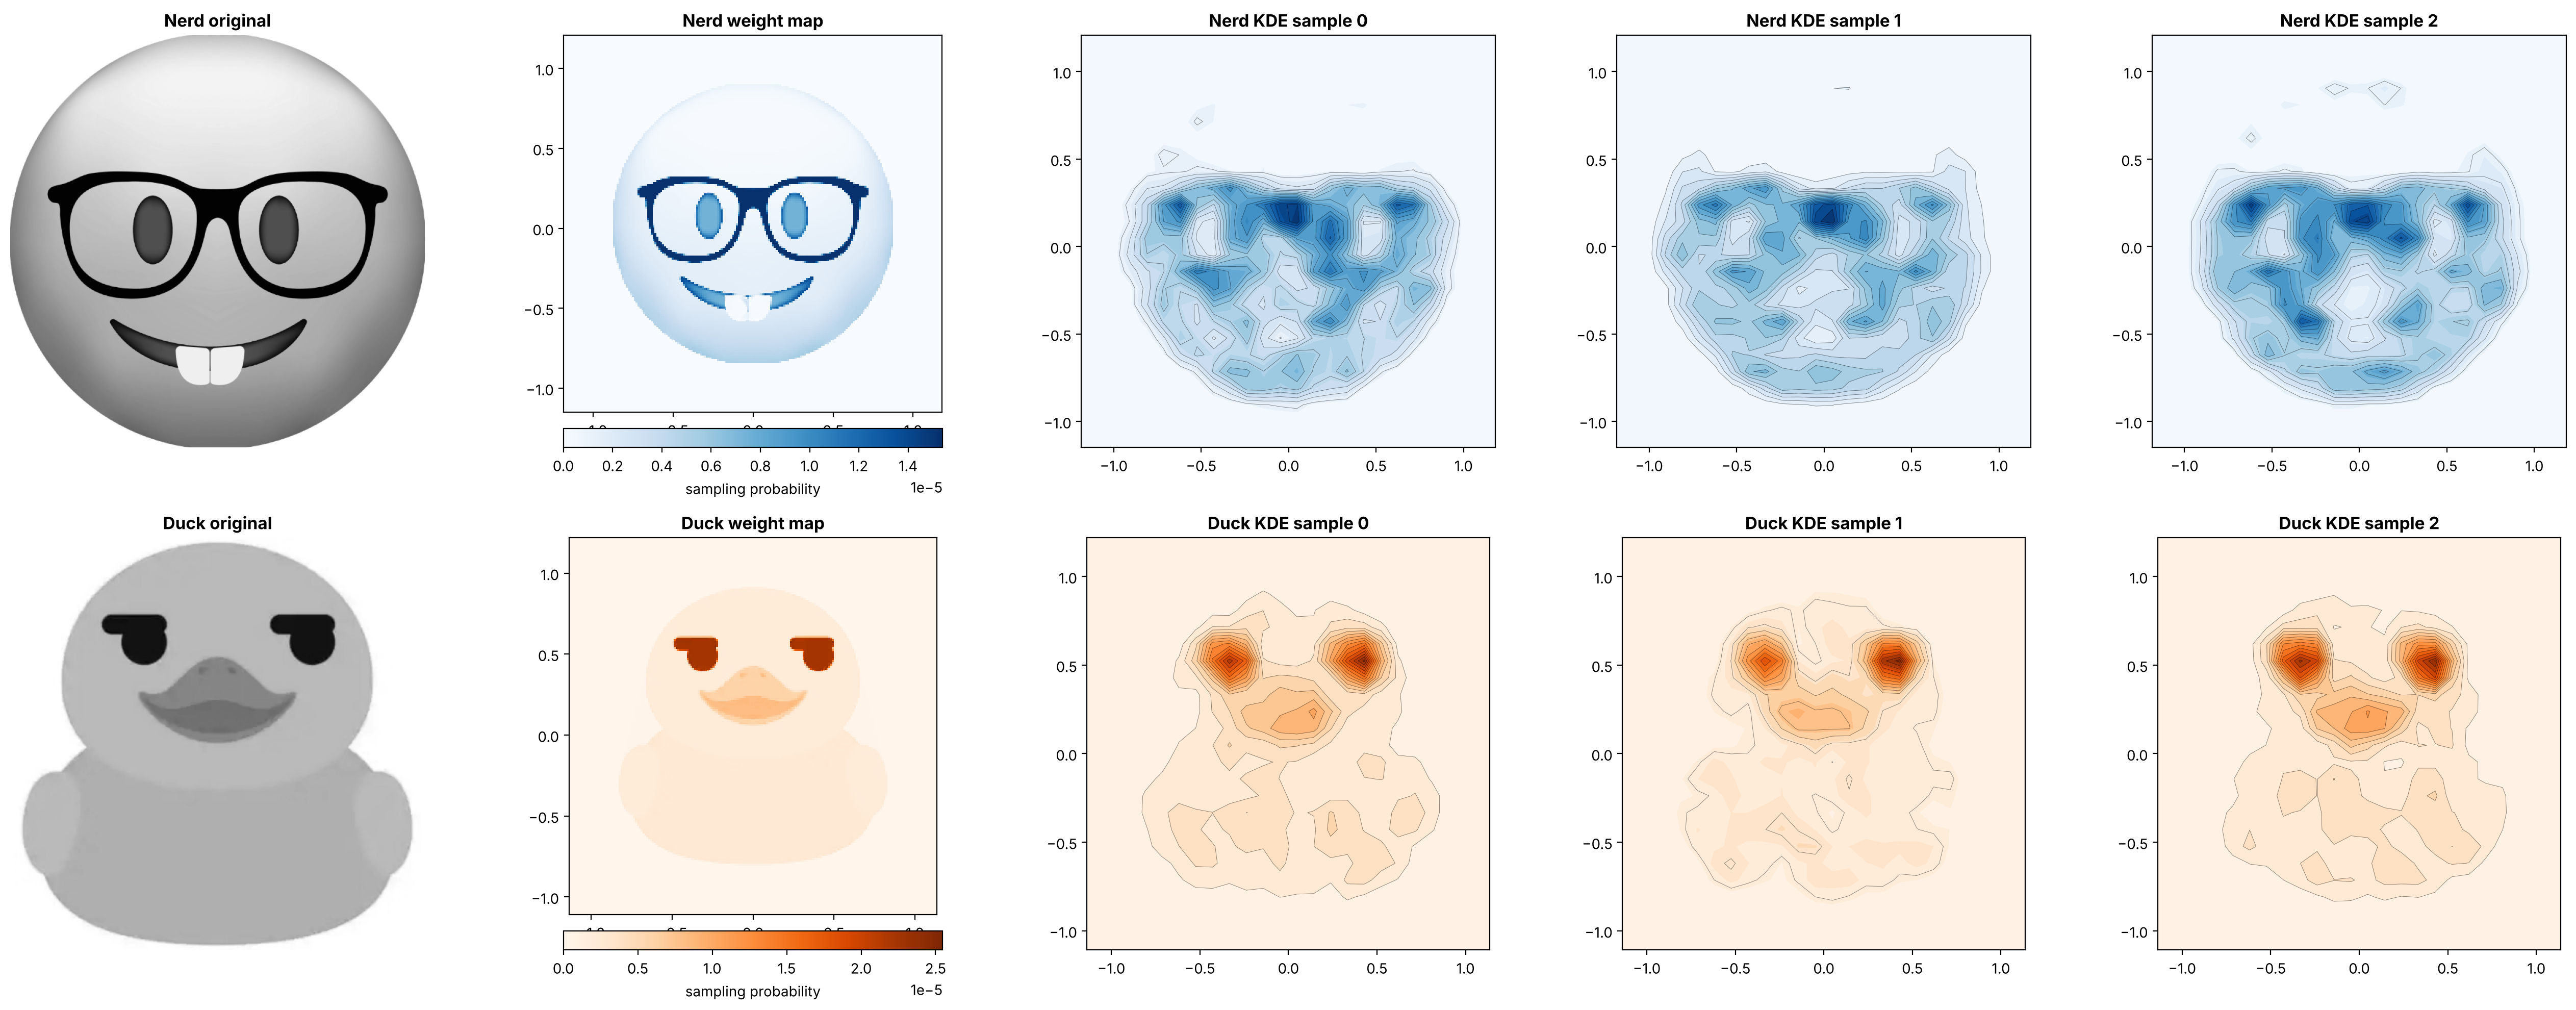

In [3]:
from scipy.interpolate import griddata

fig, axes = plt.subplots(2, 5, figsize=(26, 10))
for row, (img, xy, probs, kd, cmap, name) in enumerate([
    (nerd, nerd_xy, nerd_probs, kdes_nerd, "Blues", "Nerd"),
    (duck, duck_xy, duck_probs, kdes_duck, "Oranges", "Duck"),
]):
    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title(f"{name} original", fontweight="bold")
    axes[row, 0].axis("off")

    pad = 0.3
    xmin, xmax = xy[:, 0].min() - pad, xy[:, 0].max() + pad
    ymin, ymax = xy[:, 1].min() - pad, xy[:, 1].max() + pad
    gx, gy = np.meshgrid(np.linspace(xmin, xmax, 200), np.linspace(ymin, ymax, 200))
    wm = griddata(xy, probs, (gx, gy), method="linear", fill_value=0)
    im = axes[row, 1].imshow(wm, extent=[xmin, xmax, ymin, ymax], origin="lower", cmap=cmap)
    axes[row, 1].set_title(f"{name} weight map", fontweight="bold")
    plt.colorbar(im, ax=axes[row, 1], orientation="horizontal", fraction=0.046, pad=0.04).set_label("sampling probability")

    for i in range(3):
        ax = axes[row, i + 2]
        ax.contourf(xx, yy, kd[i], levels=20, cmap=cmap)
        ax.contour(xx, yy, kd[i], levels=15, colors="black", linewidths=0.3, alpha=0.5)
        ax.set_title(f"{name} KDE sample {i}", fontweight="bold")
        ax.set_aspect("equal"); ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)

plt.tight_layout()
plt.savefig(f"{FIG}/2d_images_to_kdes.png", dpi=120, bbox_inches="tight")
plt.show()

## 3. K-means with reverse KL barycenters (K = 2)

The reverse KL barycenter of distributions $P_1,\dots,P_n$ is

$$
q^b=\arg\min_q \sum_{i}\mathrm{KL}(q\,\|\,P_i)\;\propto\;\exp\Big(\tfrac1n\sum_i\log P_i\Big),
$$

the normalised **geometric mean**. The Lloyd algorithm alternates two steps, each of which can only lower the objective $\sum_i \mathrm{KL}(C_{z_i}\,\|\,P_i)$:

1. **Assignment:** $z_i=\arg\min_k \mathrm{KL}(C_k\,\|\,P_i)$.
2. **Update:** $C_k=$ reverse KL barycenter of $\{P_i: z_i=k\}$.

We stop when the assignments no longer change.

In [4]:
def kl_divergence(p, q):
    # KL(p || q); all inputs have a positive floor, so this is finite
    return np.sum(p * np.log(p / q))

def reverse_kl_barycenter(members):
    g = np.exp(np.mean([np.log(m) for m in members], axis=0))
    return g / g.sum()

def k_barycenters(distributions, K=2, max_iter=50, seed=0, init="kde",
                  update=reverse_kl_barycenter, verbose=True):
    rng = np.random.default_rng(seed)
    n = len(distributions)

    if init == "kde":                      # K of the input densities
        init_idx = rng.choice(n, size=K, replace=False)
        centroids = [distributions[i].copy() for i in init_idx]
        if verbose: print(f"  Init: input densities {init_idx}")
    elif init == "random_pixel":           # random distributions on the grid
        centroids = []
        for _ in range(K):
            raw = rng.exponential(1.0, size=distributions[0].shape)
            centroids.append(raw / raw.sum())
        if verbose: print("  Init: random distributions on the grid")

    labels = None
    history, log = [[c.copy() for c in centroids]], []
    for it in range(max_iter):
        new_labels = np.array([np.argmin([kl_divergence(c, P) for c in centroids]) for P in distributions])
        if labels is not None and np.array_equal(new_labels, labels):
            if verbose: print(f"  Converged: assignments unchanged at iteration {it}")
            break
        labels = new_labels

        for k in range(K):
            members = [distributions[i] for i in range(n) if labels[i] == k]
            if members:
                centroids[k] = update(members)

        sizes = [int(np.sum(labels == k)) for k in range(K)]
        cost = sum(kl_divergence(centroids[labels[i]], distributions[i]) for i in range(n))
        log.append((it, sizes, cost))
        history.append([c.copy() for c in centroids])
        if verbose: print(f"  Iter {it}: sizes = {sizes}, total KL(C || P) = {cost:.4f}")

    return centroids, labels, history, log

def confusion(labels, K=2):
    return {f"C{k}": (int(np.sum((labels == k) & (true_labels == 0))),
                      int(np.sum((labels == k) & (true_labels == 1)))) for k in range(K)}

def plot_history(history, title, fname):
    T = len(history)
    fig, axes = plt.subplots(2, T, figsize=(4.5 * T, 8))
    axes = np.asarray(axes).reshape(2, T)
    for t in range(T):
        for k, cmap in enumerate(["Purples", "Greens"]):
            axes[k, t].contourf(xx, yy, history[t][k], levels=20, cmap=cmap)
            axes[k, t].set_aspect("equal")
            axes[k, t].set_title(("Init" if t == 0 else f"Iter {t-1}") + f" — C{k}")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{FIG}/{fname}", dpi=120, bbox_inches="tight")
    plt.show()

=== Initialised with two of the input KDEs (seed 0) ===
  Init: input densities [33 25]
  Iter 0: sizes = [36, 4], total KL(C || P) = 9.3112
  Iter 1: sizes = [20, 20], total KL(C || P) = 1.4073
  Converged: assignments unchanged at iteration 2
  (nerd, duck) per cluster: {'C0': (20, 0), 'C1': (0, 20)}


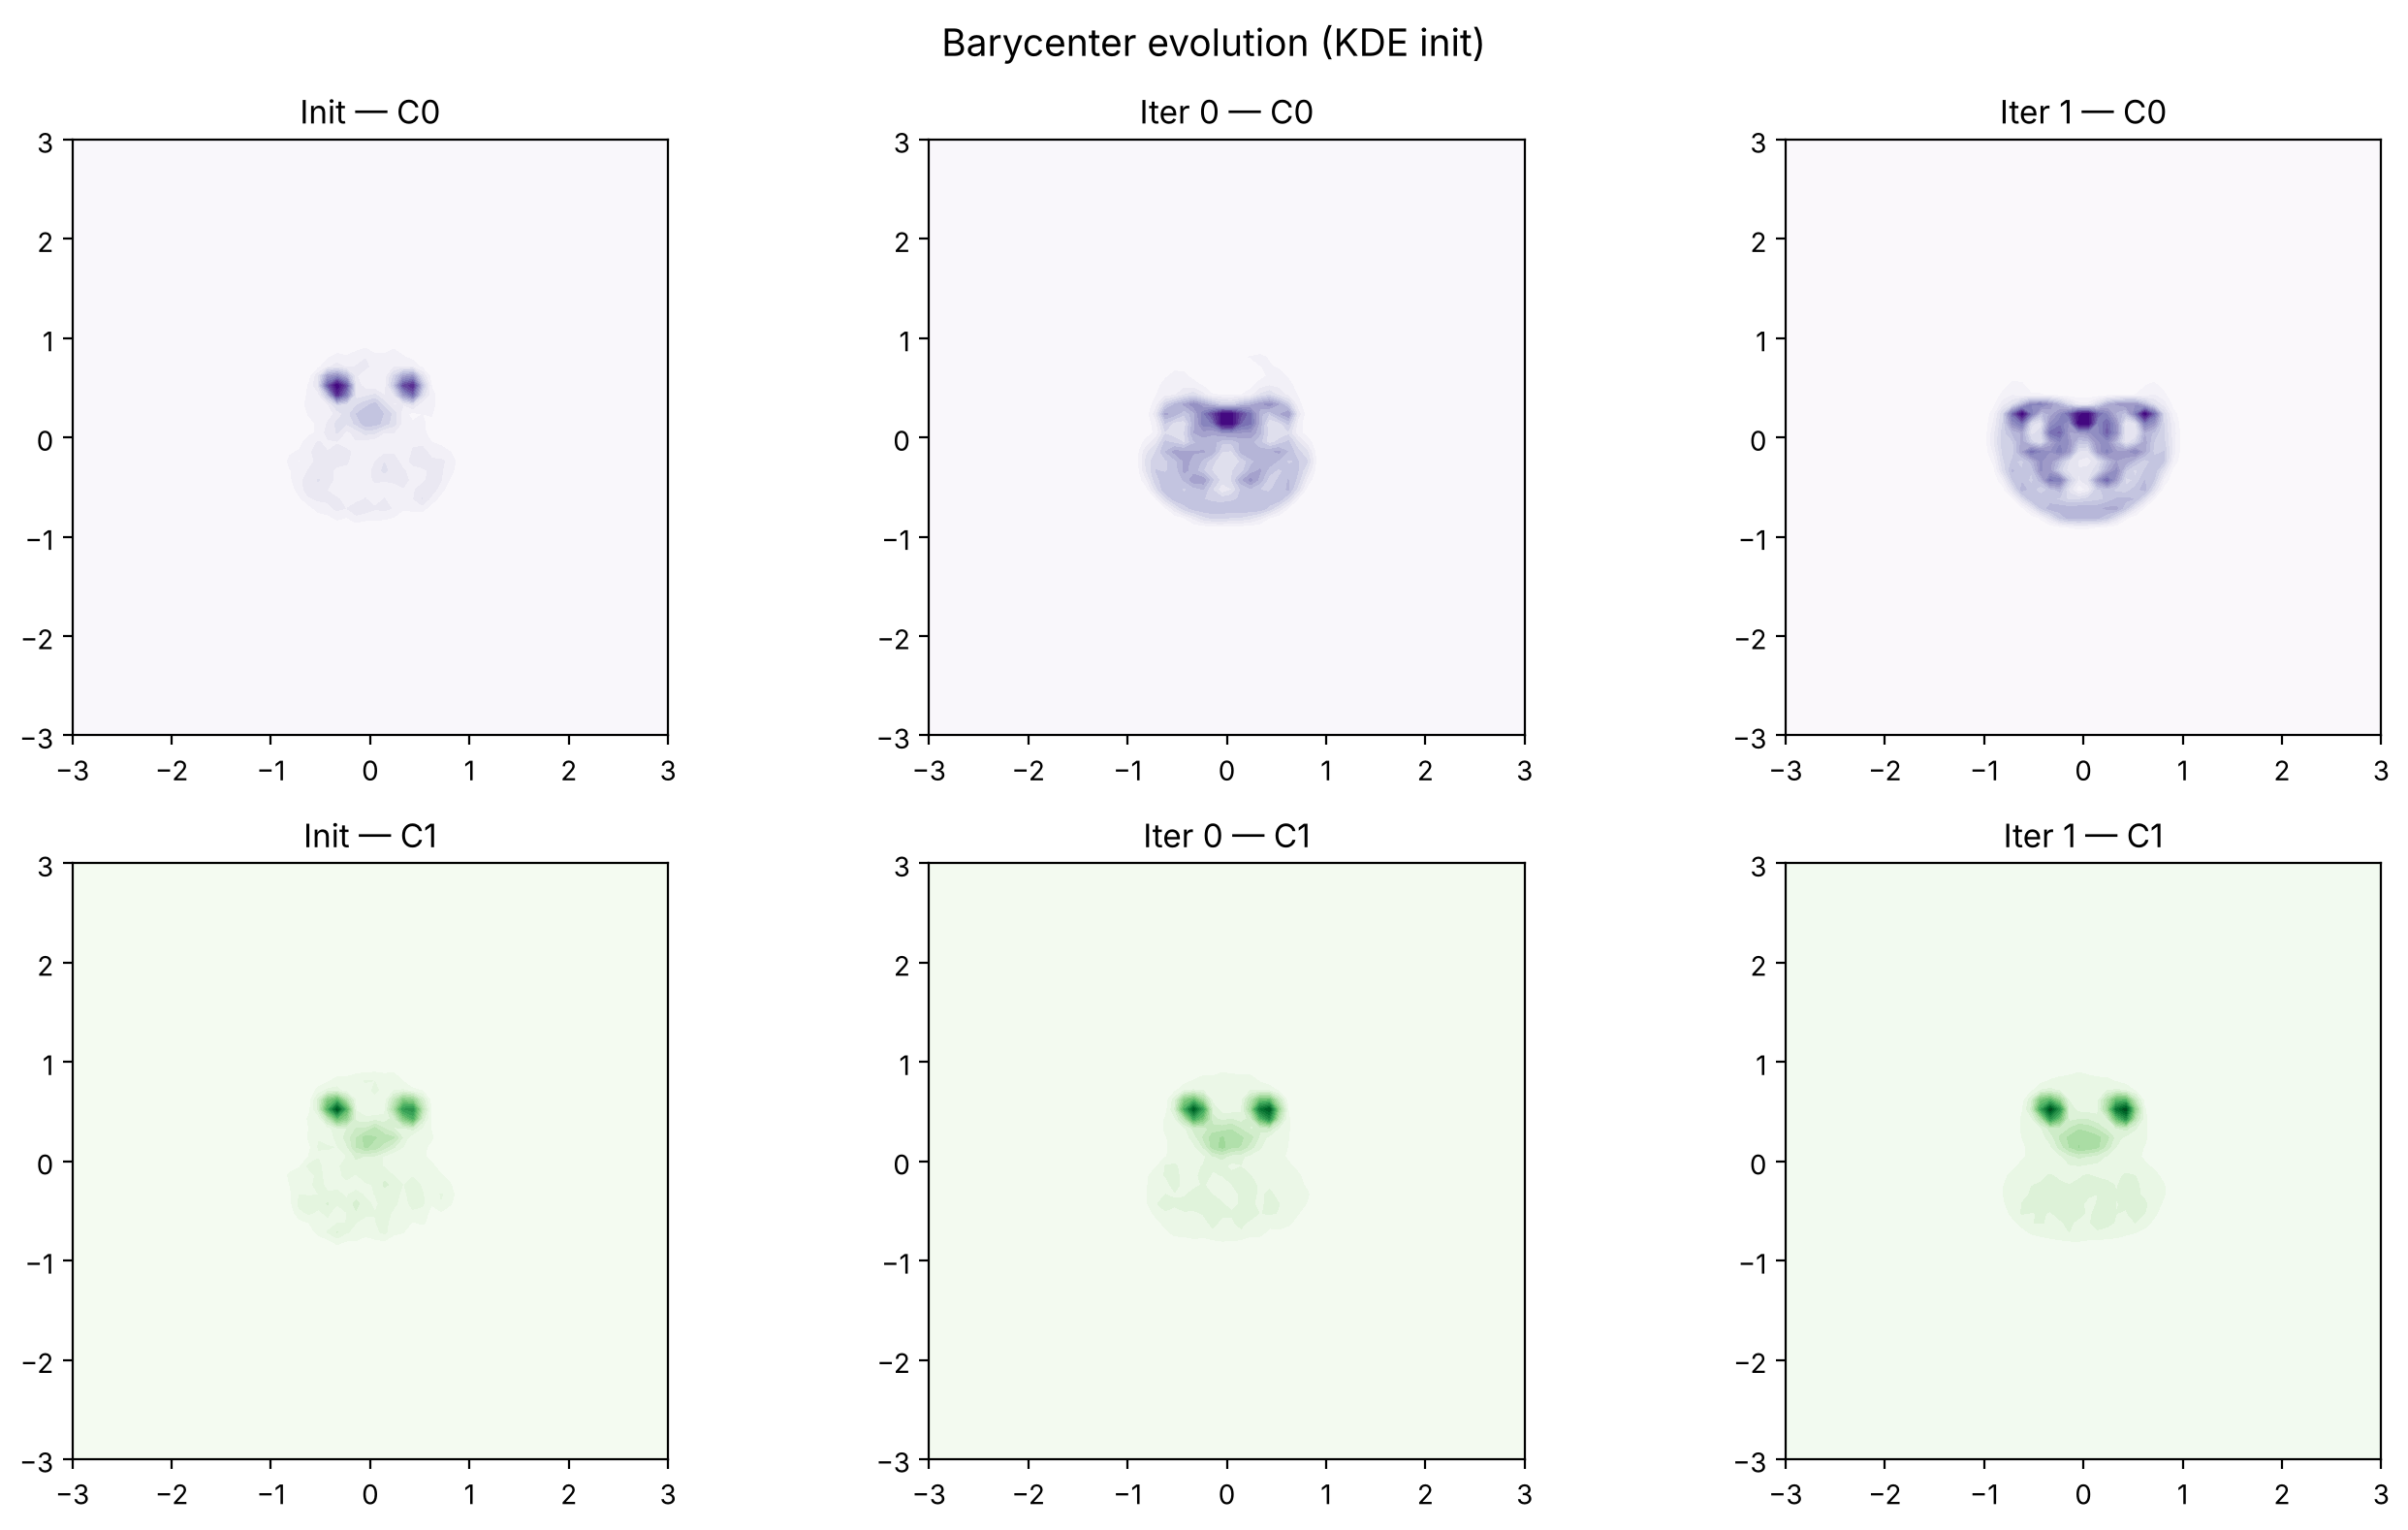

=== Initialised with random distributions (seed 42) ===
  Init: random distributions on the grid
  Iter 0: sizes = [16, 24], total KL(C || P) = 10.6323
  Iter 1: sizes = [20, 20], total KL(C || P) = 1.4073
  Converged: assignments unchanged at iteration 2
  (nerd, duck) per cluster: {'C0': (20, 0), 'C1': (0, 20)}


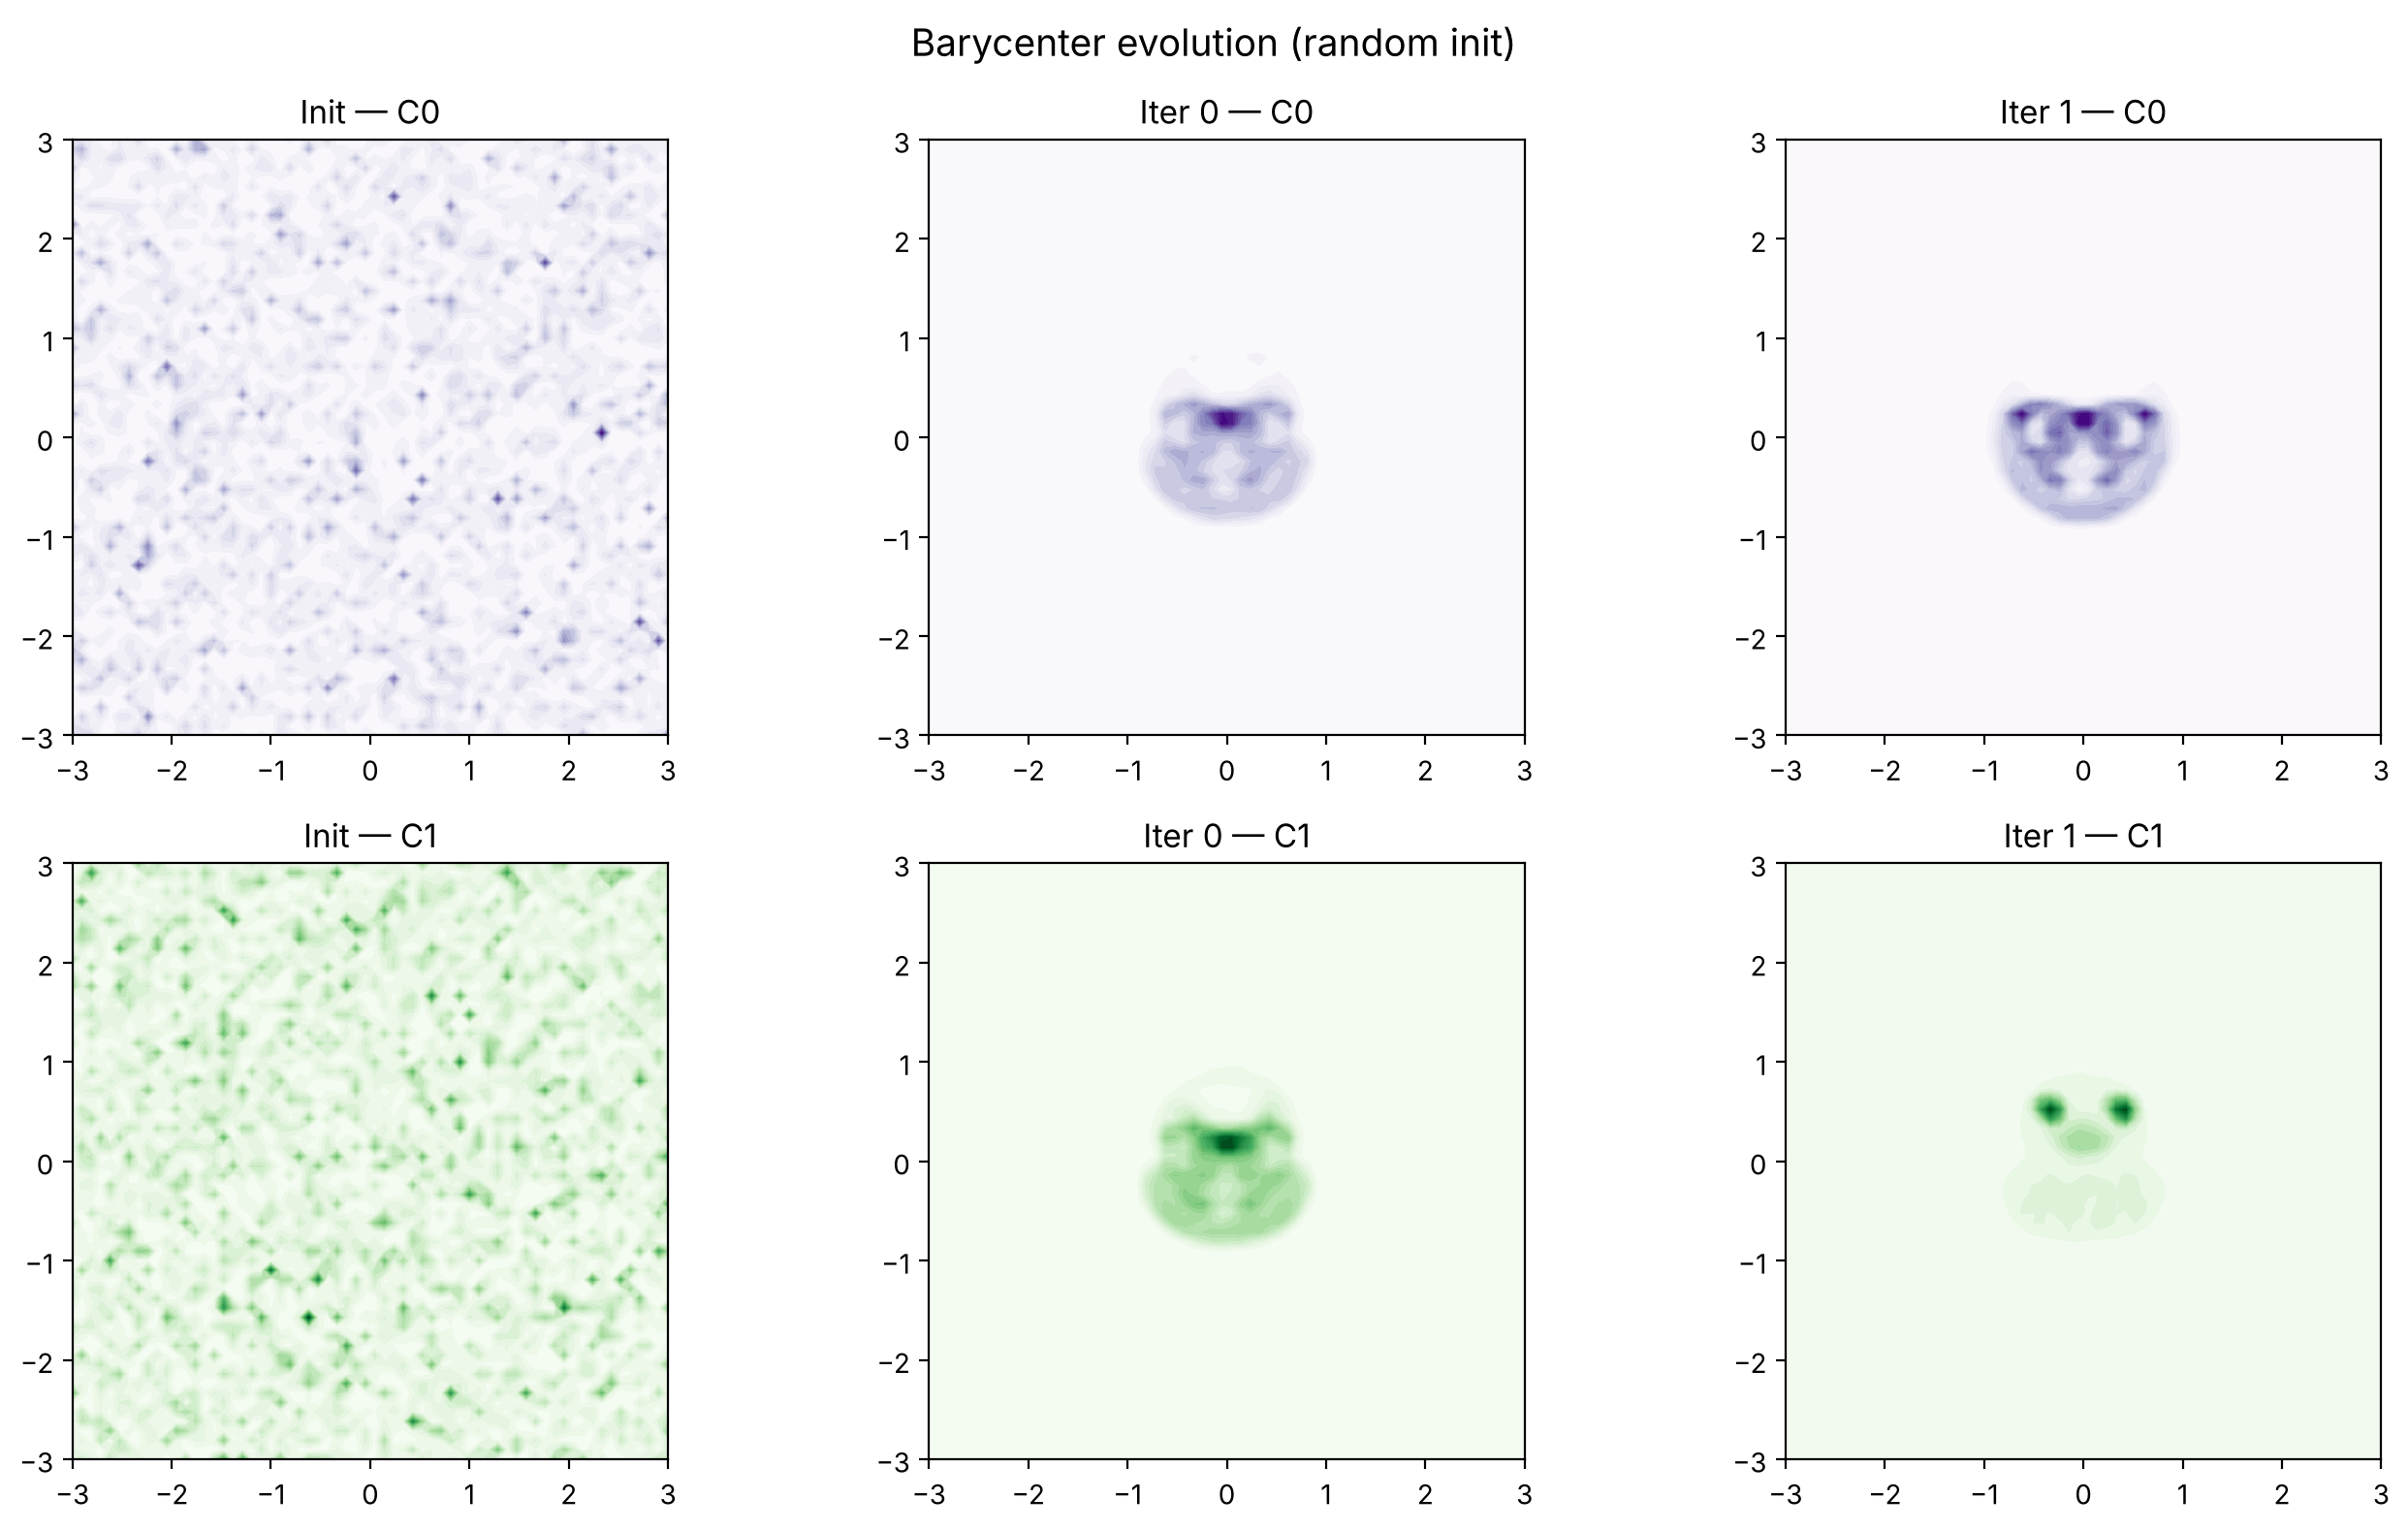

In [5]:
print("=== Initialised with two of the input KDEs (seed 0) ===")
cent_unc, labels_unc, hist_unc, log_unc = k_barycenters(all_kdes, K=2, seed=0, init="kde")
print("  (nerd, duck) per cluster:", confusion(labels_unc))
plot_history(hist_unc, "Barycenter evolution (KDE init)", "2d_evolution_kde_init.png")

print("=== Initialised with random distributions (seed 42) ===")
cent_rand, labels_rand, hist_rand, log_rand = k_barycenters(all_kdes, K=2, seed=42, init="random_pixel")
print("  (nerd, duck) per cluster:", confusion(labels_rand))
plot_history(hist_rand, "Barycenter evolution (random init)", "2d_evolution_random_init.png")

## 4. Robustness to initialisation and sample quality

With `seed=0`, the two initial centers are input densities 33 and 25, **both ducks**, so no center starts out looking like the nerd. We run this bad initialisation on two versions of the data:

- **Weighted sampling** (the pipeline above): points drawn with probability $\propto w^2$.
- **Uniform sampling**: every foreground pixel equally likely, which gives less structured KDEs.

In [6]:
kn_u, kd_u = make_kdes(weighted=False)
all_kdes_uniform = np.concatenate([kn_u, kd_u], axis=0)

for name, dists in [("Weighted sampling", all_kdes), ("Uniform sampling", all_kdes_uniform)]:
    print(f"=== {name} ===")
    _, labs, _, log = k_barycenters(dists, K=2, seed=0, init="kde")
    print("  (nerd, duck) per cluster:", confusion(labs), "\n")

=== Weighted sampling ===
  Init: input densities [33 25]
  Iter 0: sizes = [36, 4], total KL(C || P) = 9.3112
  Iter 1: sizes = [20, 20], total KL(C || P) = 1.4073
  Converged: assignments unchanged at iteration 2
  (nerd, duck) per cluster: {'C0': (20, 0), 'C1': (0, 20)} 

=== Uniform sampling ===
  Init: input densities [33 25]
  Iter 0: sizes = [6, 34], total KL(C || P) = 2.9690
  Iter 1: sizes = [20, 20], total KL(C || P) = 1.3263
  Converged: assignments unchanged at iteration 2
  (nerd, duck) per cluster: {'C0': (0, 20), 'C1': (20, 0)} 



In both cases the algorithm reaches a perfect split (20 nerd / 20 duck) and stops after the assignments stop changing, despite the bad start (see the printed sizes and costs above). The two shapes are far apart in KL compared with the sampling variation within each class, so this clustering problem is well separated.

## 5. Constrained barycenter: closed form

Sometimes we have prior information about the center, for example $P_q(X<x_0)=c$. In the update step we then solve

$$
\min_q \sum_{i\in S_k}\mathrm{KL}(q\,\|\,P_i)\quad\text{s.t.}\quad \sum_{x<x_0}\sum_y q(x,y)=c,\qquad \sum_{x,y}q(x,y)=1 .
$$

**Simplify.** With $n=|S_k|$ and $\log G=\frac1n\sum_i\log P_i$,

$$
\sum_i \mathrm{KL}(q\,\|\,P_i)=\sum_i\sum_{x,y} q\,(\log q-\log P_i)= n\sum_{x,y} q\,(\log q-\log G).
$$

**Lagrangian.** With multipliers $\alpha$ (normalisation) and $\lambda$ (the constraint),

$$
\mathcal L = n\sum q(\log q-\log G) + \alpha\Big(\sum q-1\Big)+\lambda\Big(\sum_{x<x_0} q-c\Big).
$$

Setting $\partial\mathcal L/\partial q(x,y)=0$ gives $n(\log q+1-\log G)+\alpha+\lambda\,\mathbf 1[x<x_0]=0$, so

$$
q(x,y)=G(x,y)\,\exp\!\Big(-1-\tfrac{\alpha+\lambda\mathbf 1[x<x_0]}{n}\Big),
$$

i.e. $q$ is the geometric mean $G$ times one constant on the left region and another on the right. Let $G_L=\sum_{x<x_0}G$ and $G_R=\sum_{x\ge x_0}G$. The two constraints fix the constants:

$$
\boxed{\;q^*(x,y)=\begin{cases}\dfrac{c}{G_L}\,G(x,y), & x<x_0\\[8pt]\dfrac{1-c}{G_R}\,G(x,y), & x\ge x_0\end{cases}\;}
$$

So the constrained center is the unconstrained reverse KL barycenter with the two half-planes rescaled. This is the exponential tilt $e^{-\mu h}$ from the poster with a two-valued $h$. If $G_L/(G_L+G_R)=c$ already, then $\lambda=0$ and the constraint has no effect.

=== Constrained, P(X < 0) = 0.5 ===
  Init: input densities [33 25]
  Iter 0: sizes = [36, 4], total KL(C || P) = 9.3122
  Iter 1: sizes = [20, 20], total KL(C || P) = 1.4076
  Converged: assignments unchanged at iteration 2
  left-half mass: [0.5, 0.5]
  (nerd, duck) per cluster: {'C0': (20, 0), 'C1': (0, 20)}
=== Constrained, P(X < 0) = 0.8 ===
  Init: input densities [33 25]
  Iter 0: sizes = [36, 4], total KL(C || P) = 17.1622
  Iter 1: sizes = [20, 20], total KL(C || P) = 9.0915
  Converged: assignments unchanged at iteration 2
  left-half mass: [0.8, 0.8]
  (nerd, duck) per cluster: {'C0': (20, 0), 'C1': (0, 20)}


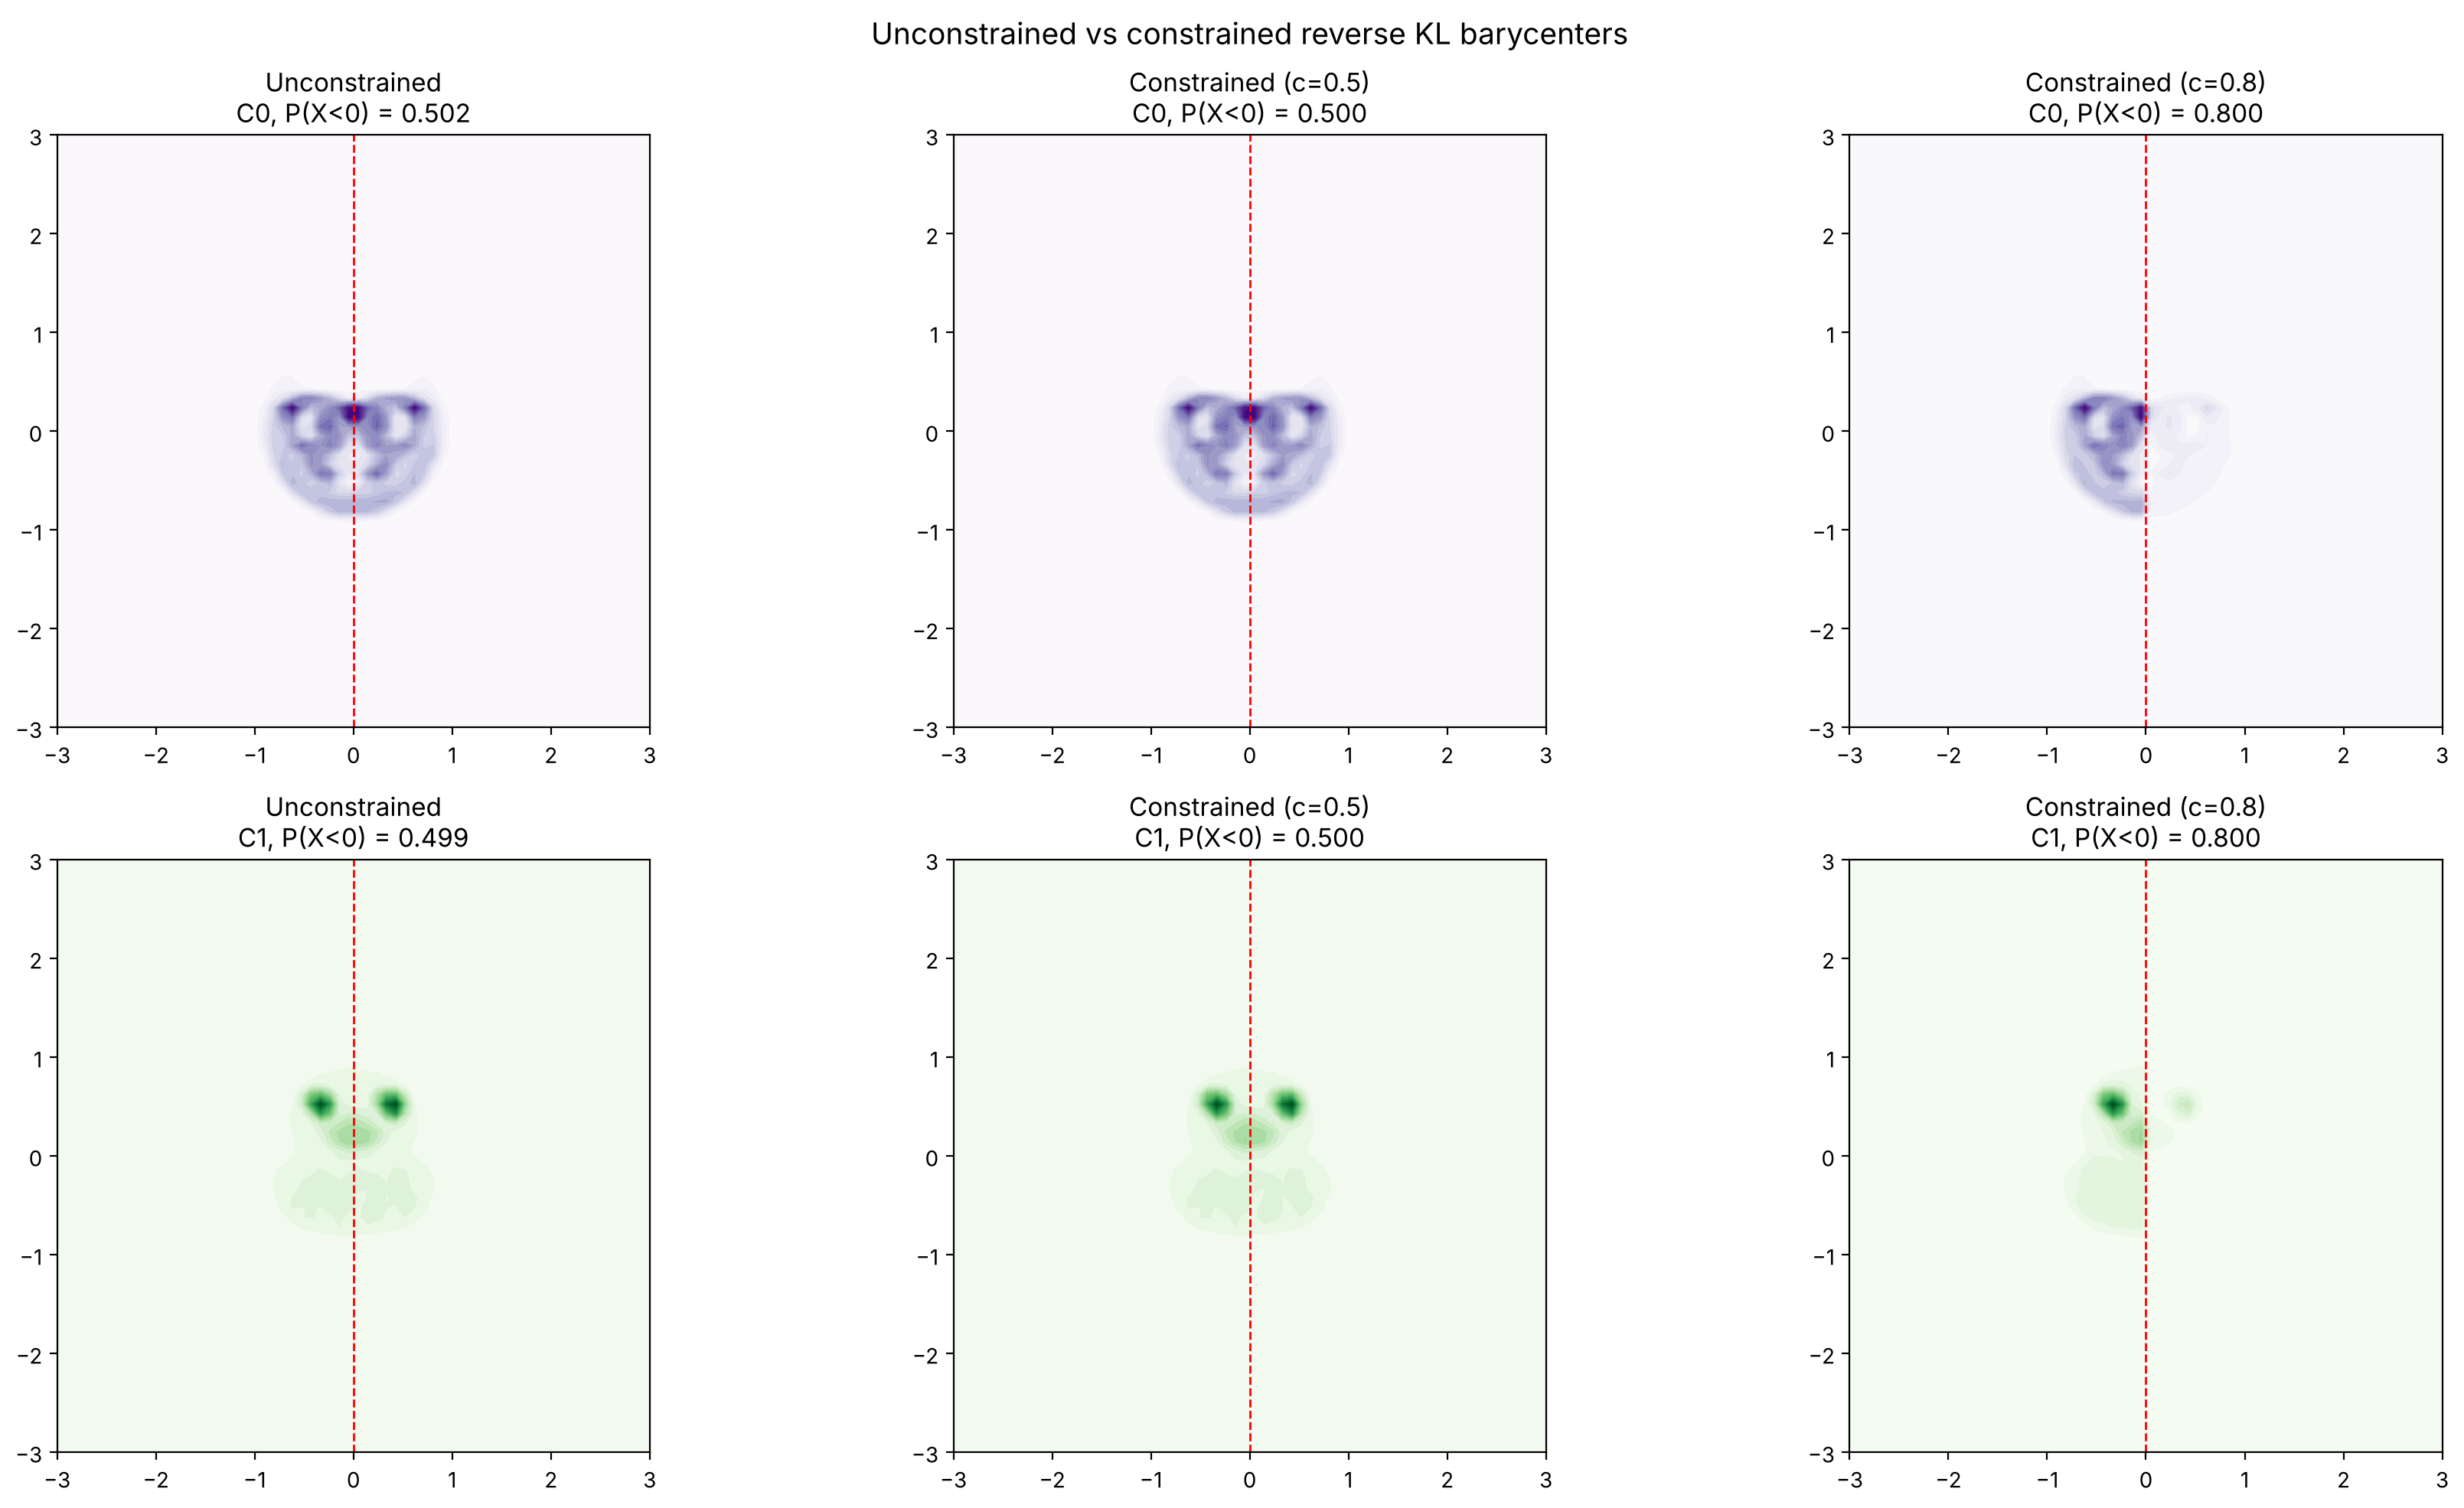

In [7]:
def constrained_update(x0, c):
    left = xx < x0
    def update(members):
        G = np.exp(np.mean([np.log(m) for m in members], axis=0))
        q = np.empty_like(G)
        q[left] = c / G[left].sum() * G[left]
        q[~left] = (1 - c) / G[~left].sum() * G[~left]
        return q
    return update

results = {"Unconstrained": (cent_unc, labels_unc)}
for c in [0.5, 0.8]:
    print(f"=== Constrained, P(X < 0) = {c} ===")
    cents, labs, _, _ = k_barycenters(all_kdes, K=2, seed=0, update=constrained_update(0.0, c))
    print("  left-half mass:", [round(float(C_[xx < 0].sum()), 6) for C_ in cents])
    print("  (nerd, duck) per cluster:", confusion(labs))
    results[f"Constrained (c={c})"] = (cents, labs)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, (title, (cents, _)) in enumerate(results.items()):
    for k, cmap in enumerate(["Purples", "Greens"]):
        axes[k, col].contourf(xx, yy, cents[k], levels=20, cmap=cmap)
        axes[k, col].axvline(0, color="red", ls="--", lw=1)
        axes[k, col].set_aspect("equal")
        axes[k, col].set_title(f"{title}\nC{k}, P(X<0) = {cents[k][xx < 0].sum():.3f}")
plt.suptitle("Unconstrained vs constrained reverse KL barycenters", fontsize=14)
plt.tight_layout()
plt.savefig(f"{FIG}/2d_constrained_vs_unconstrained.png", dpi=120, bbox_inches="tight")
plt.show()

### Tail constraint at $x_0=-0.5$

We now hold the clusters fixed (the unconstrained solution) and vary $c$ for a cut in the left tail. The first column shows each cluster's natural mass $P_{q^b}(X<-0.5)$. The further $c$ is pushed above it, the more mass is forced into the tail.

natural P(X < -0.5): [0.198, 0.103]


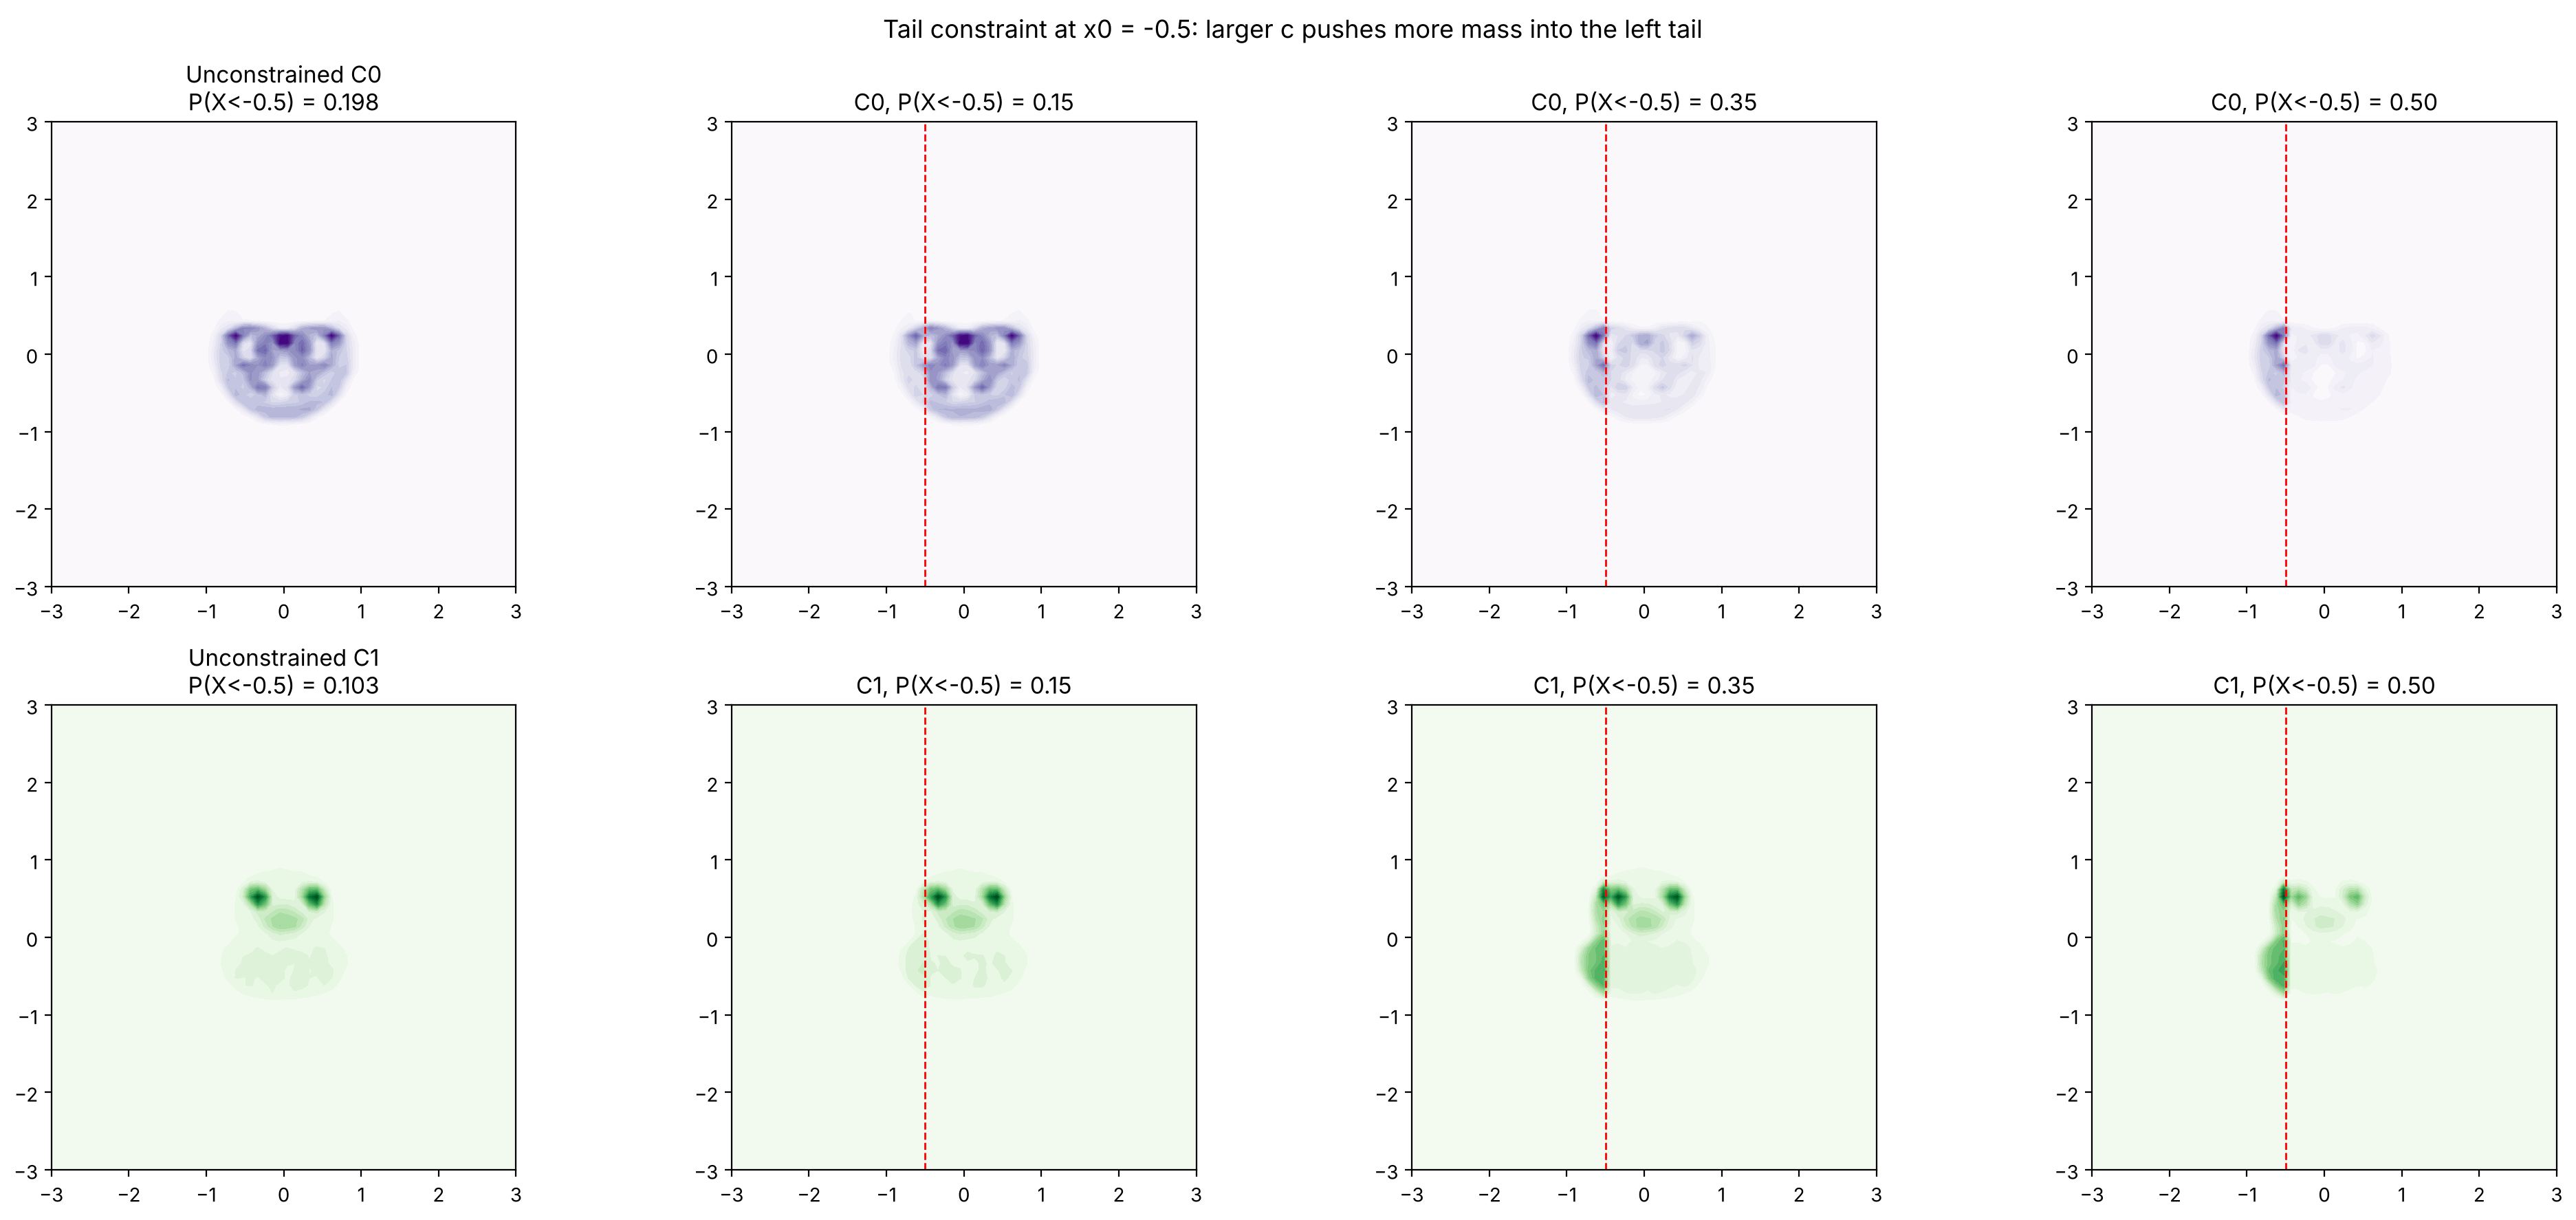

In [8]:
x0 = -0.5
qb_list = [reverse_kl_barycenter([all_kdes[i] for i in range(len(all_kdes)) if labels_unc[i] == k]) for k in range(2)]
natural = [qb[xx < x0].sum() for qb in qb_list]
print("natural P(X < -0.5):", [round(float(v), 3) for v in natural])

cs = [0.15, 0.35, 0.50]
fig, axes = plt.subplots(2, len(cs) + 1, figsize=(5 * (len(cs) + 1), 9))
for k, cmap in enumerate(["Purples", "Greens"]):
    axes[k, 0].contourf(xx, yy, qb_list[k], levels=20, cmap=cmap)
    axes[k, 0].set_title(f"Unconstrained C{k}\nP(X<{x0}) = {natural[k]:.3f}")
    axes[k, 0].set_aspect("equal")
    for col, c in enumerate(cs, 1):
        q = constrained_update(x0, c)([qb_list[k]])     # rescaling the barycenter itself
        axes[k, col].contourf(xx, yy, q, levels=20, cmap=cmap)
        axes[k, col].axvline(x0, color="red", ls="--", lw=1)
        axes[k, col].set_title(f"C{k}, P(X<{x0}) = {c:.2f}")
        axes[k, col].set_aspect("equal")
plt.suptitle(f"Tail constraint at x0 = {x0}: larger c pushes more mass into the left tail", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIG}/2d_tail_constraint.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Constrained barycenter: general constraints with a convex solver

A closed form exists only for simple constraints. In general, the update step is

$$
\min_{q\ge0}\ \sum_{i\in S_k}\mathrm{KL}(q\,\|\,P_i)\quad\text{s.t.}\quad \sum q=1,\quad g_j(q)\ (=,\le)\ c_j .
$$

From Section 5 the objective equals $n\sum q(\log q-\log G)$, so it is equivalent to

$$
\max_{q\ge0}\ \underbrace{\sum_{x,y}-q\log q}_{\text{entropy}}\;+\;\sum_{x,y} q\,\log G .
$$

The entropy is concave and the second term is linear, so this is a convex problem whenever the constraints are convex, and `cvxpy` can solve it directly (`cp.entr(q)` $=-q\log q$).

Examples of constraints the solver accepts:

| Constraint | Form | Convex? |
|---|---|---|
| Region probability | $\sum_{(x,y)\in R} q = c$ | ✓ linear |
| Mean | $\sum x\,q = \mu$ | ✓ linear |
| Probability band | $0.4\le\sum_{x<0} q\le 0.6$ | ✓ linear |
| Second moment | $\sum x^2 q \le s$ | ✓ linear |

A variance bound $\sum x^2q-(\sum xq)^2\le\sigma^2$ is **not** convex in general. If the mean is also fixed, $\sum xq=\mu$, it becomes the linear constraint $\sum x^2q\le\sigma^2+\mu^2$.

**Check:** for the constraint $P(X<0)=0.5$ the solver should reproduce the closed form from Section 5.

In [9]:
import cvxpy as cp

xx_flat, yy_flat = xx.ravel(), yy.ravel()

def constrained_barycenter_cvxpy(members, constraints_fn):
    log_G = np.mean([np.log(m) for m in members], axis=0).ravel()
    q = cp.Variable(log_G.size, nonneg=True)
    objective = cp.Maximize(cp.sum(cp.entr(q)) + log_G @ q)   # = -(1/n) * sum_i KL(q || P_i) + const
    prob = cp.Problem(objective, [cp.sum(q) == 1] + constraints_fn(q))
    prob.solve(solver=cp.CLARABEL)
    if prob.status not in ("optimal", "optimal_inaccurate"):
        print("  WARNING: solver status =", prob.status)
    qv = np.maximum(q.value, 1e-12)
    return (qv / qv.sum()).reshape(members[0].shape)

def left_half(c):
    m = (xx_flat < 0).astype(float)
    return lambda q: [m @ q == c]

def left_and_top(q):
    return [(xx_flat < 0).astype(float) @ q == 0.5, (yy_flat > 0).astype(float) @ q == 0.5]

def shifted_mean(q):
    return [xx_flat @ q == 0.5]

# 1) agreement with the closed form
members0 = [all_kdes[i] for i in range(len(all_kdes)) if labels_unc[i] == 0]
q_solver = constrained_barycenter_cvxpy(members0, left_half(0.5))
q_closed = constrained_update(0.0, 0.5)(members0)
print(f"max |solver - closed form| = {np.max(np.abs(q_solver - q_closed)):.2e}   (largest cell = {q_closed.max():.2e})")

max |solver - closed form| = 3.31e-09   (largest cell = 1.13e-02)


=== P(X<0)=0.5 and P(Y>0)=0.5 ===
  Init: input densities [33 25]


  Iter 0: sizes = [36, 4], total KL(C || P) = 9.9400


  Iter 1: sizes = [20, 20], total KL(C || P) = 2.1876
  Converged: assignments unchanged at iteration 2
  (nerd, duck) per cluster: {'C0': (20, 0), 'C1': (0, 20)}
  C0: P(X<0) = 0.500, P(Y>0) = 0.500, E[X] = -0.003, E[X^2] = 0.287
  C1: P(X<0) = 0.500, P(Y>0) = 0.500, E[X] = +0.007, E[X^2] = 0.223
=== E[X]=0.5 ===
  Init: input densities [33 25]


  Iter 0: sizes = [36, 4], total KL(C || P) = 24.3698


  Iter 1: sizes = [20, 20], total KL(C || P) = 17.1612
  Converged: assignments unchanged at iteration 2
  (nerd, duck) per cluster: {'C0': (20, 0), 'C1': (0, 20)}
  C0: P(X<0) = 0.236, P(Y>0) = 0.435, E[X] = +0.500, E[X^2] = 0.914
  C1: P(X<0) = 0.250, P(Y>0) = 0.592, E[X] = +0.500, E[X^2] = 0.988


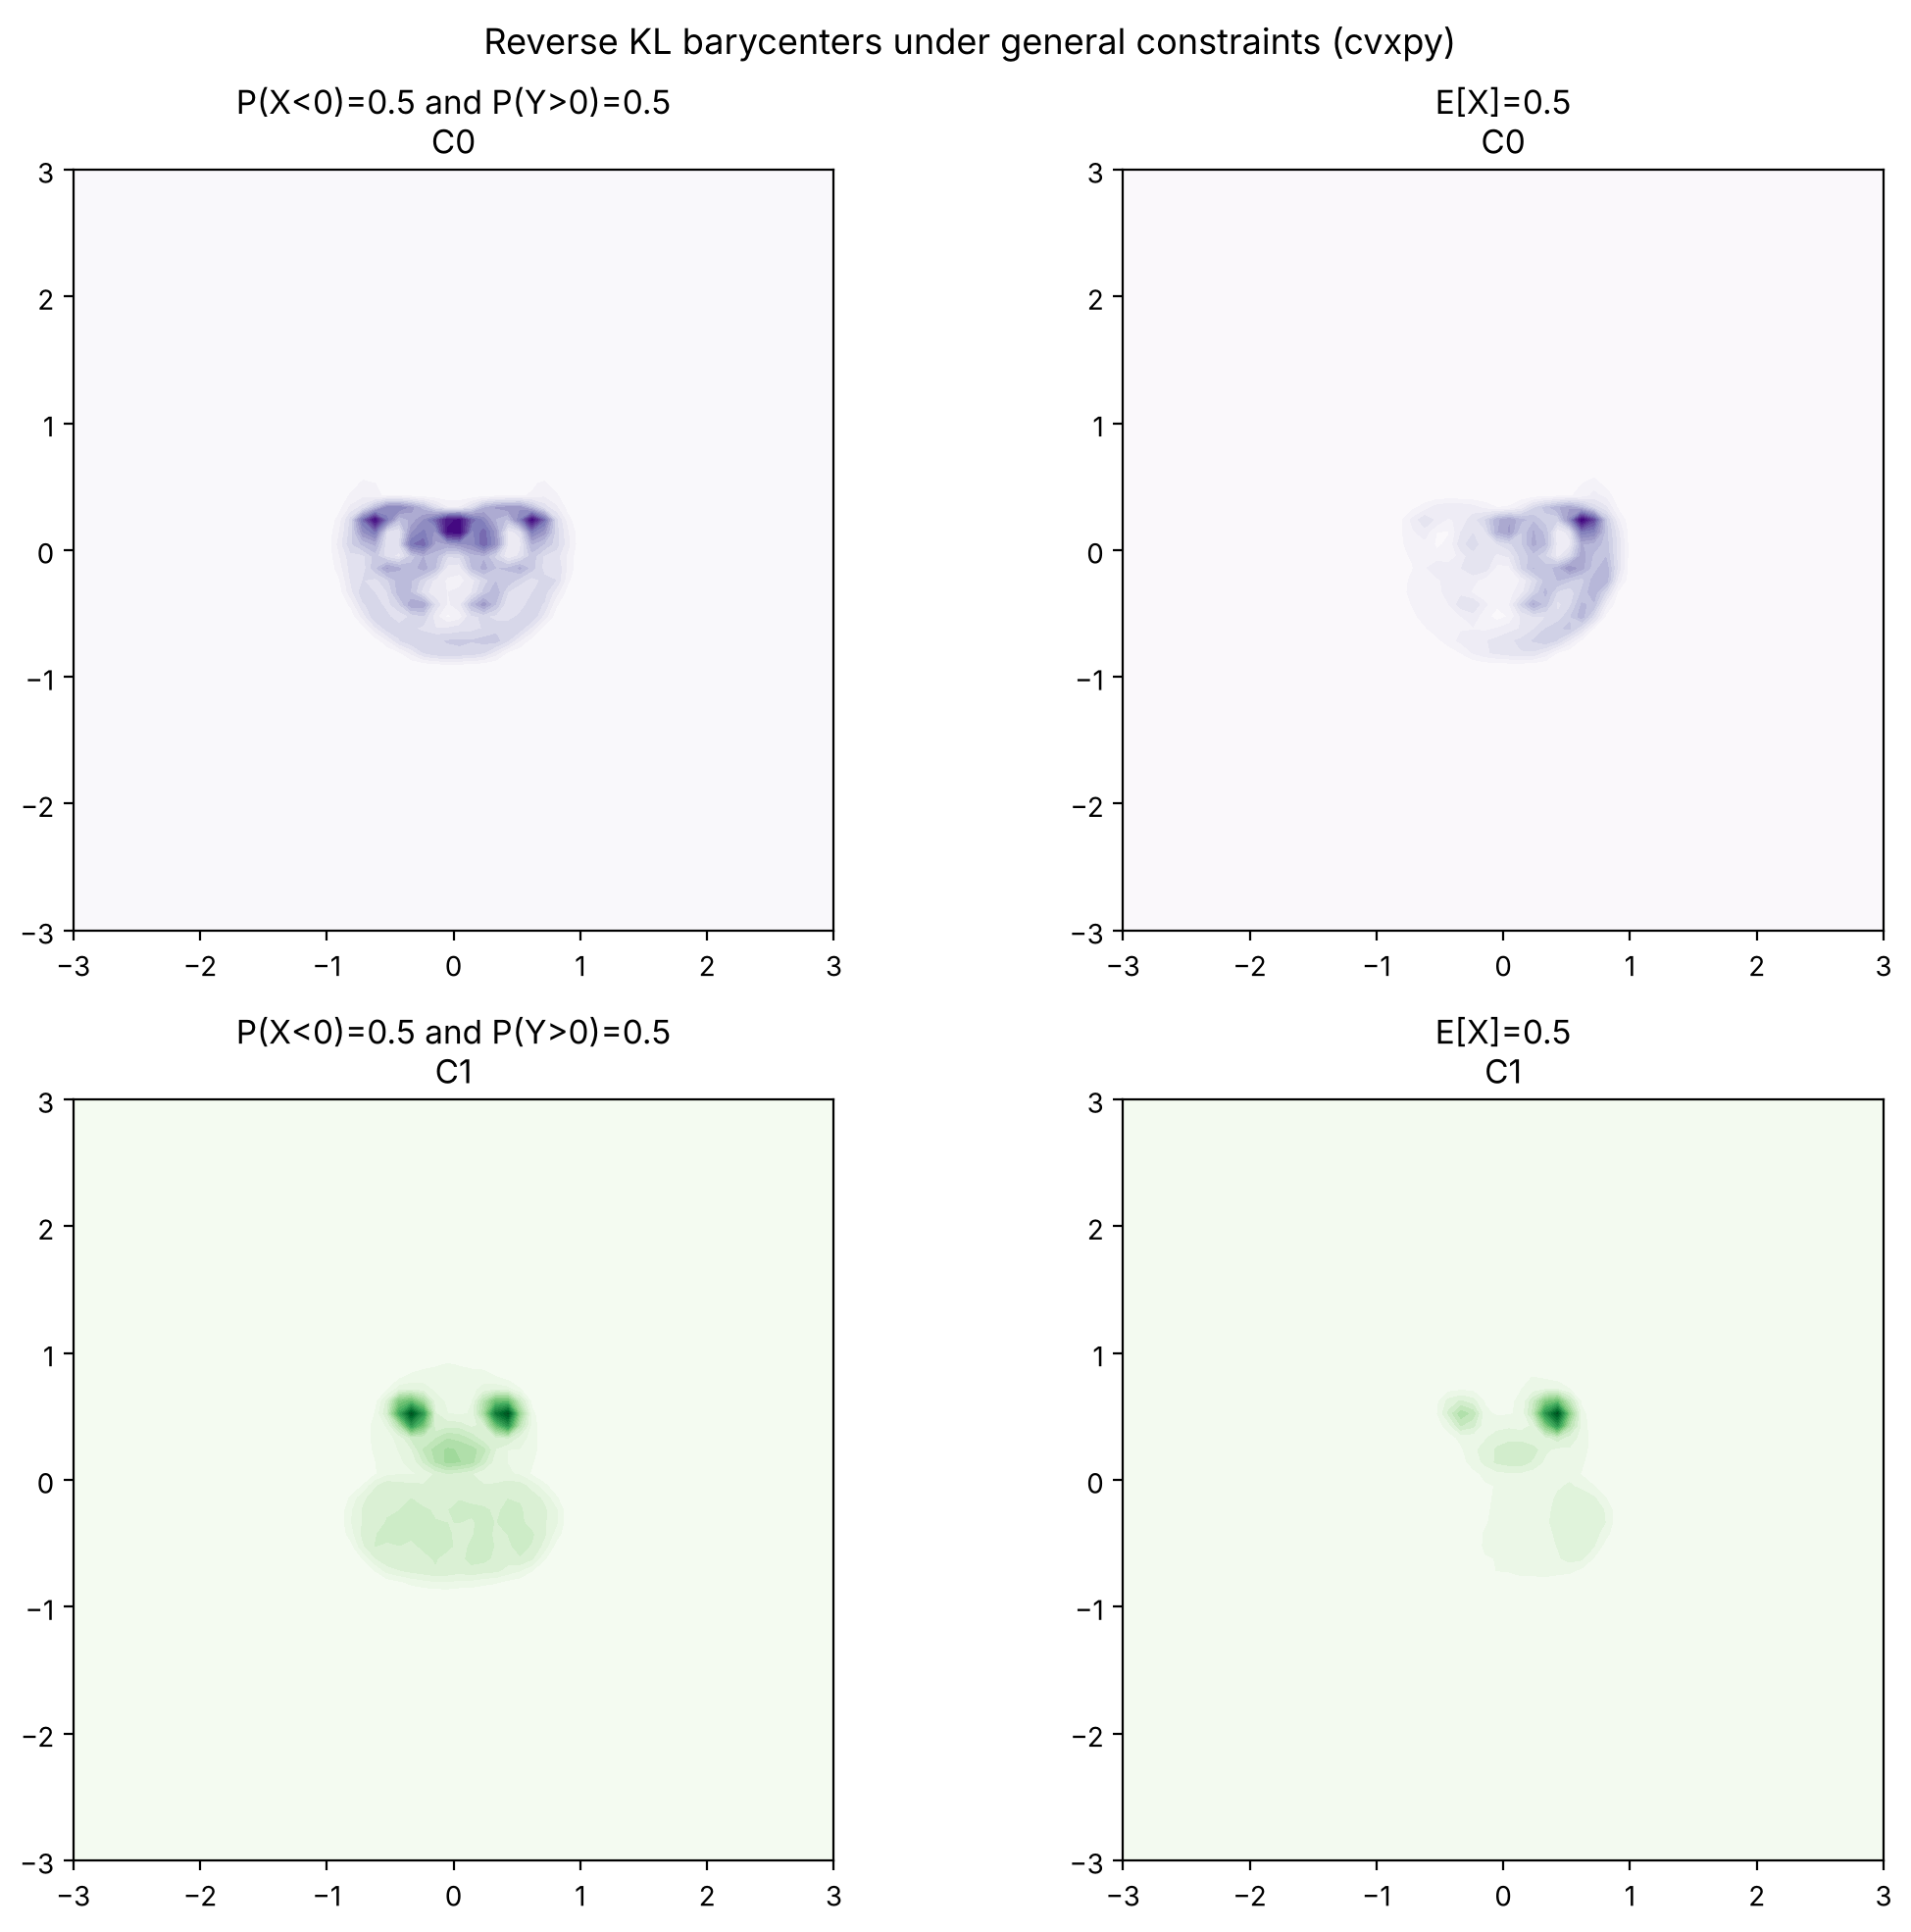

In [10]:
# 2) full clustering with constraints that have no simple closed form
for name, fn in [("P(X<0)=0.5 and P(Y>0)=0.5", left_and_top), ("E[X]=0.5", shifted_mean)]:
    print(f"=== {name} ===")
    upd = lambda members, fn=fn: constrained_barycenter_cvxpy(members, fn)
    cents, labs, _, _ = k_barycenters(all_kdes, K=2, seed=0, update=upd)
    print("  (nerd, duck) per cluster:", confusion(labs))
    for k, C_ in enumerate(cents):
        print(f"  C{k}: P(X<0) = {C_[xx < 0].sum():.3f}, P(Y>0) = {C_[yy > 0].sum():.3f}, "
              f"E[X] = {np.sum(xx * C_):+.3f}, E[X^2] = {np.sum(xx**2 * C_):.3f}")
    results[name] = (cents, labs)

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for col, name in enumerate(["P(X<0)=0.5 and P(Y>0)=0.5", "E[X]=0.5"]):
    for k, cmap in enumerate(["Purples", "Greens"]):
        axes[k, col].contourf(xx, yy, results[name][0][k], levels=20, cmap=cmap)
        axes[k, col].set_aspect("equal")
        axes[k, col].set_title(f"{name}\nC{k}")
plt.suptitle("Reverse KL barycenters under general constraints (cvxpy)", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIG}/2d_cvxpy_constraints.png", dpi=120, bbox_inches="tight")
plt.show()